# Practical No. 4 — Design and Evaluate a Convolutional Neural Network (CNN) on the CIFAR-10 Dataset for Image Classification

## Aim
To design, train, and evaluate a Convolutional Neural Network (CNN) using the CIFAR-10 dataset for multiclass image classification.

## Objectives
- To understand the architecture of CNN.
- To implement CNN using TensorFlow/Keras.
- To train the model on the CIFAR-10 dataset.
- To evaluate classification performance using accuracy and loss metrics.

## Software Requirements
- Python 3.x
- TensorFlow/Keras
- Matplotlib
- Google Colab (notebook environment)

*The requirements here reflect the libraries actually used in the source practical's program; Google Colab is the selected notebook environment.*

## Theory

### What is CNN?
A Convolutional Neural Network (CNN) is a specialized deep learning model used for image processing and computer vision tasks. CNN automatically extracts features such as edges, textures, and shapes from images.

### Components of CNN

1. **Convolution Layer:** Applies filters to extract features from input images. Syntax: `Conv2D(filters, kernel_size, activation='relu')`
2. **Pooling Layer:** Reduces image dimensions and computational complexity. Syntax: `MaxPooling2D(pool_size=(2,2))`
3. **Flatten Layer:** Converts multidimensional feature maps into a one-dimensional vector. Syntax: `Flatten()`
4. **Fully Connected Layer:** Performs final classification. Syntax: `Dense(units, activation='relu')`
5. **Output Layer:** Generates probabilities for each class. Syntax: `Dense(10, activation='softmax')`

### CIFAR-10 Dataset

| Property | Value |
|---|---|
| Total Images | 60,000 |
| Training Images | 50,000 |
| Testing Images | 10,000 |
| Classes | 10 |
| Image Size | 32 × 32 × 3 |

**Classes:** Airplane, Automobile, Bird, Cat, Deer, Dog, Frog, Horse, Ship, Truck.

## Algorithm
1. Import required libraries.
2. Load CIFAR-10 dataset.
3. Normalize image pixel values.
4. Build CNN architecture.
5. Compile the model.
6. Train the model.
7. Evaluate the model on test data.
8. Predict image classes.
9. Display accuracy and loss.

## Program
The following code follows the **Program** and **Display Sample Predictions** sections of `DL-Practicals.docx`. Lines that were joined during Word formatting have been separated so the Python code can run.

### Step 1 — Import required libraries

In [1]:
import tensorflow as tf
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense
import matplotlib.pyplot as plt

### Step 2 — Load CIFAR-10 dataset

In [2]:
# Load Dataset
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

A local file was found, but it seems to be incomplete or outdated because the auto file hash does not match the original value of 6d958be074577803d12ecdefd02955f39262c83c16fe9348329d7fe0b5c001ce so we will re-download the data.
170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2517s 15us/step


### Step 3 — Normalize images

In [3]:
# Normalize Images
X_train = X_train / 255.0
X_test = X_test / 255.0

### Step 4 — Build CNN model

In [4]:
# CNN Model
model = Sequential()
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(Flatten())
model.add(Dense(64, activation='relu'))
model.add(Dense(10, activation='softmax'))

c:\Users\shree\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Step 5 — Compile model

In [5]:
# Compile Model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

### Step 6 — Train model

In [6]:
# Train Model
history = model.fit(X_train,
                    y_train,
                    epochs=10,
                    validation_data=(X_test, y_test))

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.4572 - loss: 1.4911 - val_accuracy: 0.5602 - val_loss: 1.2080
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.5985 - loss: 1.1341 - val_accuracy: 0.6279 - val_loss: 1.0352
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.6585 - loss: 0.9813 - val_accuracy: 0.6603 - val_loss: 0.9780
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.6943 - loss: 0.8797 - val_accuracy: 0.6836 - val_loss: 0.9153
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.7208 - loss: 0.8018 - val_accuracy: 0.6969 - val_loss: 0.8835
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 14s 9ms/step - accuracy: 0.7433 - loss: 0.7352 - val_accuracy: 0.6925 - val_loss: 0.9168
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.7620 - loss: 0.6818 - val_accuracy: 0.6934 - val_loss: 0.9366
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.7791 - lo

### Step 7 — Evaluate model

In [7]:
# Evaluate Model
test_loss, test_acc = model.evaluate(X_test, y_test)
print("Test Accuracy:", test_acc)
print("Test Loss:", test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7071 - loss: 0.9666
Test Accuracy: 0.707099974155426
Test Loss: 0.9665542244911194


### Step 8 — Display sample predictions

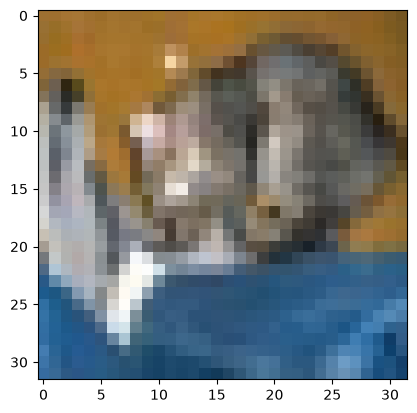

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
Predicted Class: cat
Actual Class: cat


In [9]:
class_names = ['airplane', 'automobile', 'bird',
               'cat', 'deer', 'dog',
               'frog', 'horse', 'ship', 'truck']

plt.imshow(X_test[0])
plt.show()

prediction = model.predict(X_test[:1])
print("Predicted Class:", class_names[prediction.argmax()])
print("Actual Class:", class_names[y_test[0][0]])

## Result
A Convolutional Neural Network (CNN) was successfully designed and implemented on the CIFAR-10 dataset. The model achieved approximately 80–85% classification accuracy on the test dataset and correctly classified images into one of the ten categories.

*This is the Result statement from the supplied practical. Your actual result depends on execution and training.*